In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
listings_raw = pd.read_csv('../data/listings_clean_outlier.csv', parse_dates=['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review'])
listings = listings_raw.copy()
print(listings.shape)

(4574, 74)


over_300_reviews    91
dtype: int64


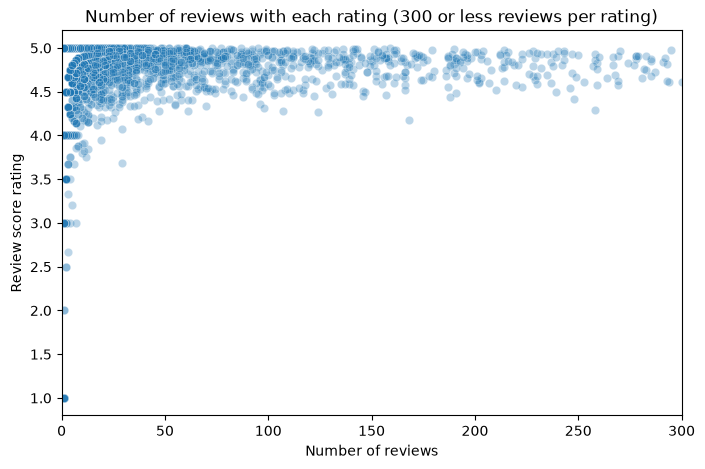

In [14]:
print(listings[listings.has_reviews].groupby('review_scores_rating').apply(lambda x: pd.Series(dict(
    over_300_reviews=((x.number_of_reviews > 300)).sum()))).sum())

fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(data=listings[listings.has_reviews], x='number_of_reviews', y='review_scores_rating', alpha=0.3, ax=ax)
ax.set_xlim(0,300)
ax.set_title('Number of reviews with each rating (300 or less reviews per rating)')
ax.set_ylabel('Review score rating')
ax.set_xlabel('Number of reviews')
plt.show()

Listings that have any reveiws under 4.0 generally have a lot fewer total reviews.
Most reviews are between 4.0 and 5.0


# 2)

                   less_or_equal_300_reviews
host_is_superhost                           
False                                   3171
True                                     668
                   over_300_reviews
host_is_superhost                  
False                            44
True                             47


C:\Users\stoop\AppData\Local\Temp\ipykernel_25648\4046581381.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['other hosts (3171 (+44 above 300))','superhosts (668 (+47 above 300))'])


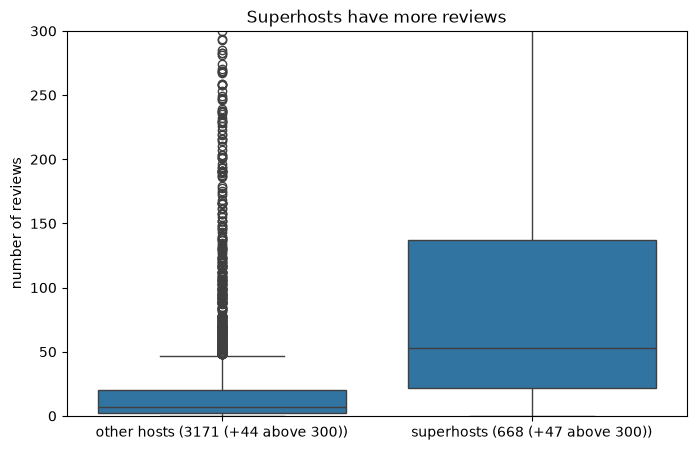

In [72]:
print(listings[listings.has_reviews].groupby('host_is_superhost').apply(lambda x: pd.Series(dict(
    less_or_equal_300_reviews=(x.number_of_reviews <= 300).sum()))))
print(listings[listings.has_reviews].groupby('host_is_superhost').apply(lambda x: pd.Series(dict(
    over_300_reviews=((x.number_of_reviews > 300)).sum()))))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=listings, x='host_is_superhost', y='number_of_reviews', ax=ax)
ax.set_xticklabels(['other hosts (3171 (+44 above 300))','superhosts (668 (+47 above 300))'])
ax.set_title('Superhosts have more reviews')
ax.set_ylim(0, 300)
ax.set_xlabel('')
ax.set_ylabel('number of reviews')
plt.show()

Superhosts have more reviews than other hosts on average.
We cannot say that becoming a superhost will give you more reviews.

# 3 a)

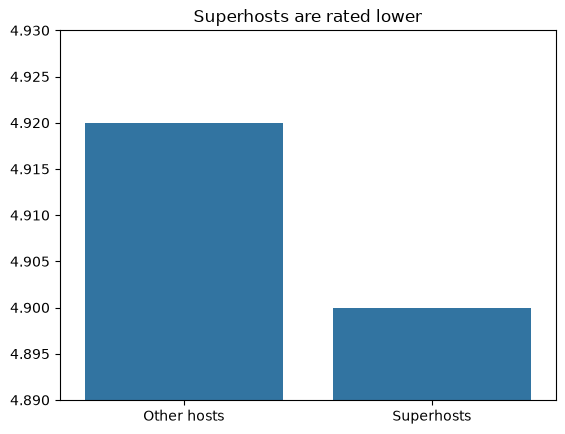

In [73]:
medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()
fig, ax = plt.subplots()
sns.barplot(x=['Other hosts', 'Superhosts'], y=medians.values, ax=ax)
ax.set_ylim(4.89, 4.93)
ax.set_title('Superhosts are rated lower')
plt.show()

* No y-label
* Y-axis starts at 4.890, so it's misleading by making the bar look very different in height.
* The graph doesn't tell how much data is behind these bars.

# b)

host_is_superhost
False    3215
True      715
Name: count, dtype: int64


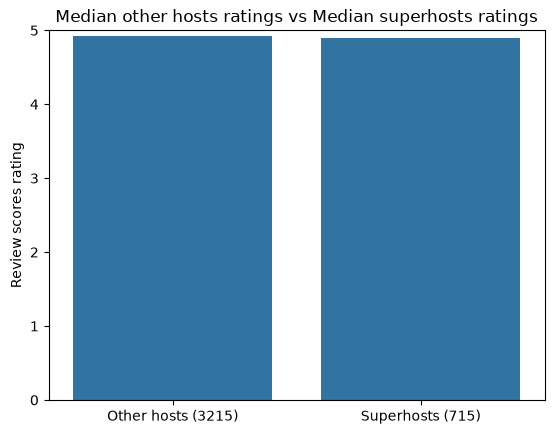

In [77]:
print(listings[listings.has_reviews].host_is_superhost.value_counts())

medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()
fig, ax = plt.subplots()
sns.barplot(x=['Other hosts (3215)', 'Superhosts (715)'], y=medians.values, ax=ax)
ax.set_ylim(0, 5)
ax.set_ylabel('Review scores rating')
ax.set_title('Median other hosts ratings vs Median superhosts ratings')
plt.show()

In [79]:
listings[listings.has_reviews].groupby('host_is_superhost').agg(
    number_of_listings=('review_scores_rating', 'count'),
    median=('review_scores_rating', 'median'),
    mean=('review_scores_rating', 'mean'),
).round(2)

,number_of_listings,median,mean
host_is_superhost,,,
False,3215,4.92,4.81
True,715,4.90,4.87


Superhosts mean rating is higher than other hosts mean rating

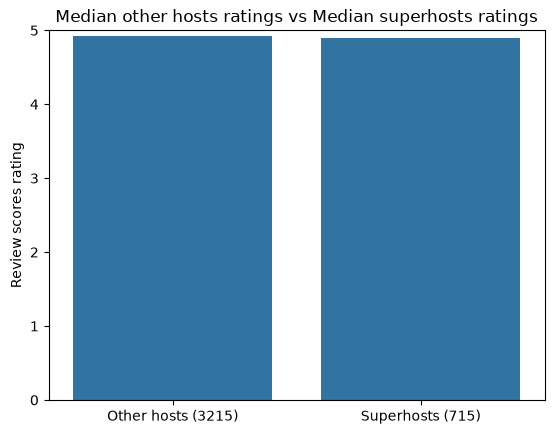

In [19]:
medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()
fig, ax = plt.subplots()
sns.barplot(x=['Other hosts (3215)', 'Superhosts (715)'], y=medians.values, ax=ax)
ax.set_ylim(0, 5)
ax.set_ylabel('Review scores rating')
ax.set_title('Median other hosts ratings vs Median superhosts ratings')
plt.savefig('../data/median_review_scores_superhosts.png', dpi=150, bbox_inches='tight')

# 4)

Text(0.5, 1.0, 'Mean price per neighbourhood')

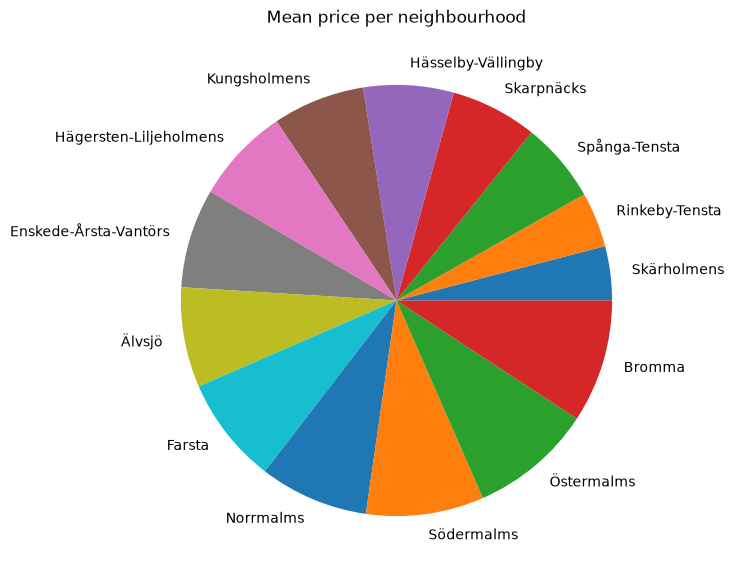

In [18]:
neighbourhoods = listings.groupby('neighbourhood_cleansed')['price'].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(neighbourhoods.values, labels=neighbourhoods.index)
ax.set_title('Mean price per neighbourhood')